# Can words help a model find objects?

We compare two small object detection models on the same two photos.

**Plan**
0. Setup
1. Look at the photos
2. A normal model: it only knows a fixed list of objects
3. A model that reads words: it looks for what we write
4. Good words vs. bad words: does the wording change the result?
5. Try your own words

### Before you start (once)

1. Install [uv](https://docs.astral.sh/uv/).
2. In a terminal, inside this folder, run: `uv sync`
3. Open this notebook and select the Python environment in `.venv` as the kernel.
4. Run the cells in order, from top to bottom.

The first run downloads: YOLO26n (5.5 MB), YOLOE-26n (11.7 MB) and a text model (254 MB).
All libraries and models come from official sources (PyPI and Ultralytics), with exact versions saved in `uv.lock`.

### Key words

| Word | Meaning | Example |
|---|---|---|
| Class | A type of object the model can name | `cat` |
| Box | A rectangle around a found object | A box around the cat |
| Confidence | How sure the model is, from 0 to 1 | `cat 0.91` = 91% sure |
| Prompt | The words given to the model | `["cat", "flower"]` |
| Vector | A list of numbers that stands for a word | `"cat"` → `[0.12, -0.40, ...]` |

## 0. Setup

Just run this cell. It prepares everything.
It should print: `Using this folder's uv environment: True`.
If it prints `False` or shows an error, choose the `.venv` kernel (top right) and run it again.

In [15]:
import sys
print("Using this folder's uv environment:", ".venv" in sys.executable)

# Tools
import os
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO, YOLOE

# The two photos
IMAGES = ["example1.jpeg", "example2.jpeg"]


# Helper: draw each photo with its boxes, then list what was found (example: "cat 0.91")
def show(results):
    for r in results:
        plt.figure(figsize=(5, 6))
        plt.imshow(r.plot()[:, :, ::-1])  # [:, :, ::-1] fixes the colours
        plt.title(os.path.basename(r.path))
        plt.axis("off")
        plt.show()
        for box in r.boxes:
            name = r.names[int(box.cls.item())]
            confidence = round(box.conf.item(), 2)
            print(name, confidence)

Using this folder's uv environment: True


## 1. Look at the photos

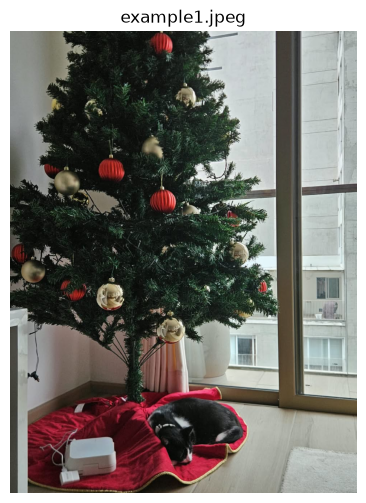

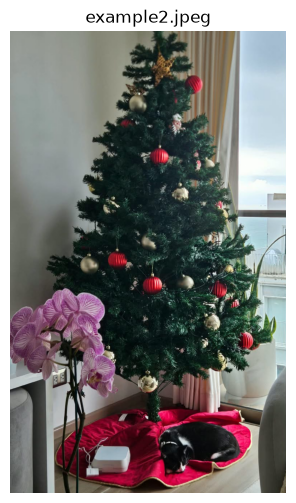

In [16]:
for image in IMAGES:
    plt.figure(figsize=(5, 6))
    plt.imshow(plt.imread(image))
    plt.title(image)
    plt.axis("off")
    plt.show()

**Look at:** both photos have a christmas tree and a cat. Only `example2.jpeg` has a flower (a pink orchid).

## 2. A normal model (YOLO26n)

It can only name objects from its fixed list of 80.
Example: "cat" is on the list. "christmas tree" is not.

In [17]:
yolo = YOLO("yolo26n.pt")

print("Knows 'cat'?", "cat" in yolo.names.values())
print("Knows 'christmas tree'?", "christmas tree" in yolo.names.values())
print("Knows 'flower'?", "flower" in yolo.names.values())
print()
print("Its full list:", list(yolo.names.values()))

Knows 'cat'? True
Knows 'christmas tree'? False
Knows 'flower'? False

Its full list: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


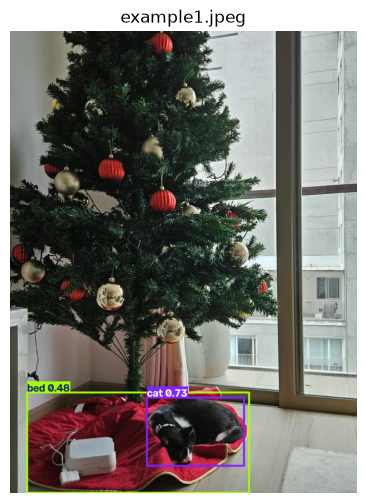

cat 0.73
bed 0.48


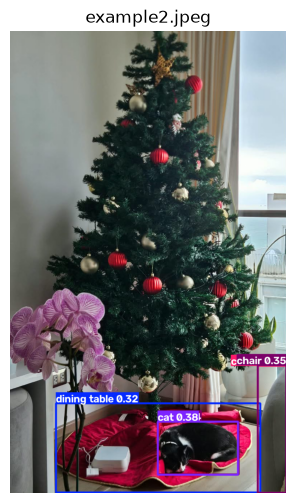

cat 0.38
chair 0.35
couch 0.34
dog 0.34
dining table 0.32


In [19]:
results = yolo(IMAGES, verbose=False)  # verbose=False hides technical messages
show(results)

## 3. A model that reads words (YOLOE-26n)

We give it words. It turns each word into a vector (a list of numbers) and looks for objects that match.

In [5]:
yoloe = YOLOE("yoloe-26n-seg.pt")

# Peek inside: the word "cat" as numbers
numbers = yoloe.get_text_pe(["cat"]).flatten()
print("'cat' becomes", len(numbers), "numbers. The first five:", numbers[:5])

c:\Users\demo5\Documents\Apps\Case-YOLO\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


'cat' becomes 512 numbers. The first five: tensor([-0.0022,  0.0147,  0.0646,  0.0086, -0.0301])


Now it looks for: ['christmas tree', 'cat', 'flower']


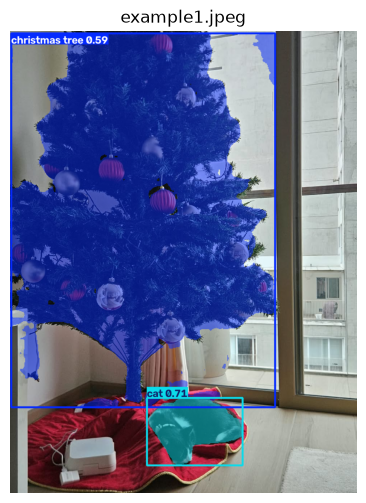

cat 0.71
christmas tree 0.59


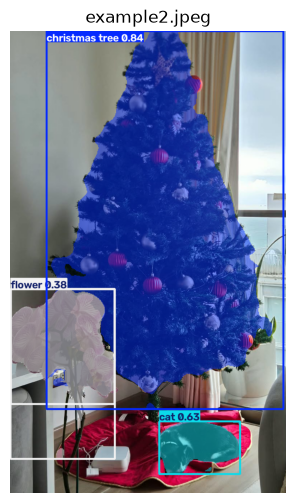

christmas tree 0.84
cat 0.63
flower 0.38
flower 0.31


In [20]:
words = ["christmas tree", "cat", "flower"]
yoloe.set_classes(words)  # these words become the list of objects to find
print("Now it looks for:", list(yoloe.names.values()))

results = yoloe(IMAGES, verbose=False)
show(results)

**Look at:** now the tree and the flower can be named, because we wrote those words.

## 4. Good words vs. bad words

Same model, same photos. Only the words change.
Each prompt is tested alone, and we keep the highest confidence in each photo.

| Type | Example | Meaning |
|---|---|---|
| specific | `christmas tree` | The exact name |
| generic | `tree` | A broader word |
| sentence | `a decorated christmas tree with red and gold balls` | A long description |
| typo | `chrismas tre` | A spelling mistake |
| wrong | `palm tree` | Something that is **not** in the photo |

In [7]:
TESTS = [  # (object, type, prompt)
    ("tree", "specific", "christmas tree"),
    ("tree", "generic", "tree"),
    ("tree", "sentence", "a decorated christmas tree with red and gold balls"),
    ("tree", "typo", "chrismas tre"),
    ("tree", "wrong", "palm tree"),
    ("cat", "specific", "black and white cat"),
    ("cat", "generic", "animal"),
    ("cat", "sentence", "a black and white cat sleeping on a red blanket"),
    ("cat", "typo", "catt"),
    ("cat", "wrong", "dog"),
    ("flower", "specific", "pink orchid"),
    ("flower", "generic", "flower"),
    ("flower", "sentence", "pink orchid flowers in a pot"),
    ("flower", "typo", "orkid"),
    ("flower", "wrong", "sunflower"),
]


# Highest confidence in one photo (0 if nothing was found)
def best_score(result):
    if len(result.boxes) == 0:
        return 0.0
    return round(result.boxes.conf.max().item(), 2)


rows = []
for obj, kind, prompt in TESTS:
    yoloe.set_classes([prompt])  # look for this prompt only
    photo1, photo2 = yoloe(IMAGES, conf=0.01, verbose=False)  # conf=0.01 keeps even unsure answers
    rows.append([obj, kind, prompt, best_score(photo1), best_score(photo2)])

scores = pd.DataFrame(rows, columns=["object", "type", "prompt", "example1", "example2"])
scores

,object,type,prompt,example1,example2
0,tree,specific,christmas tree,0.59,0.84
1,tree,generic,tree,0.28,0.08
2,tree,sentence,a decorated christmas tree with red and gold b...,0.49,0.68
3,tree,typo,chrismas tre,0.09,0.39
4,tree,wrong,palm tree,0.00,0.00
5,cat,specific,black and white cat,0.55,0.43
6,cat,generic,animal,0.49,0.29
7,cat,sentence,a black and white cat sleeping on a red blanket,0.45,0.49
8,cat,typo,catt,0.25,0.30
9,cat,wrong,dog,0.69,0.59


In [45]:
scores

,object,type,prompt,example1,example2
0,tree,specific,christmas tree,0.59,0.84
1,tree,generic,tree,0.28,0.08
2,tree,sentence,a decorated christmas tree with red and gold b...,0.49,0.68
3,tree,typo,chrismas tre,0.09,0.39
4,tree,wrong,palm tree,0.00,0.00
5,cat,specific,black and white cat,0.55,0.43
6,cat,generic,animal,0.49,0.29
7,cat,sentence,a black and white cat sleeping on a red blanket,0.45,0.49
8,cat,typo,catt,0.25,0.30
9,cat,wrong,dog,0.69,0.59


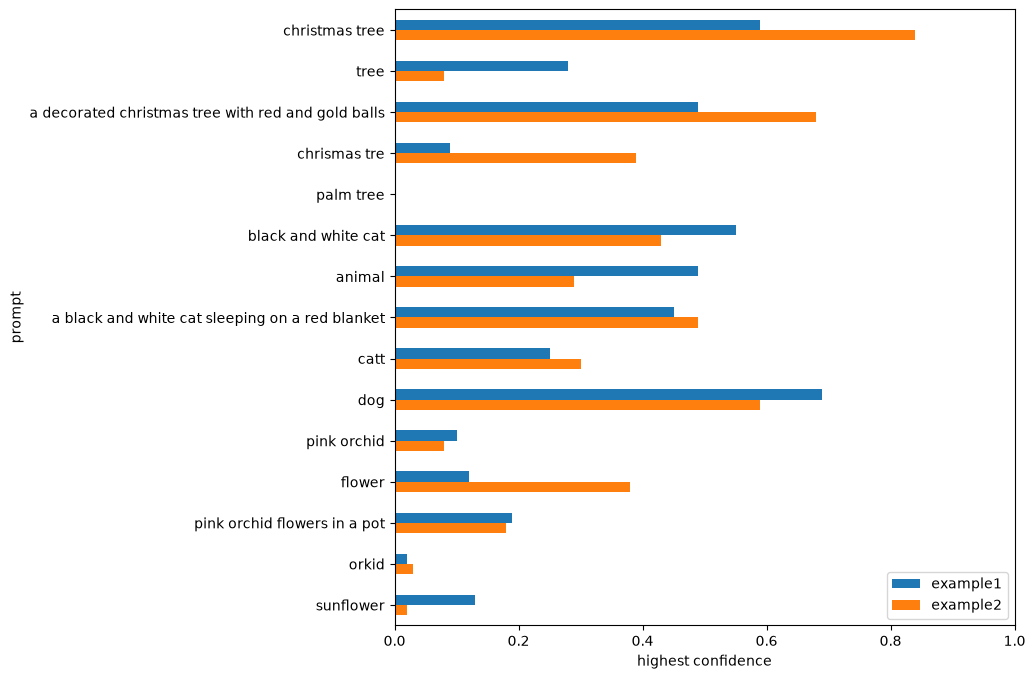

In [43]:
scores.plot.barh(x="prompt", y=["example1", "example2"], figsize=(8, 8), xlim=(0, 1))
plt.gca().invert_yaxis()  # same order as the table
plt.xlabel("highest confidence")
plt.show()

## 5. Try different own words

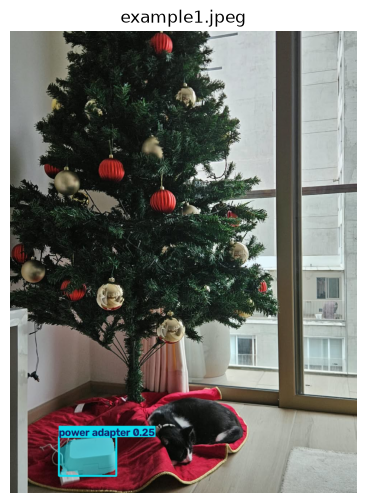

power adapter 0.25


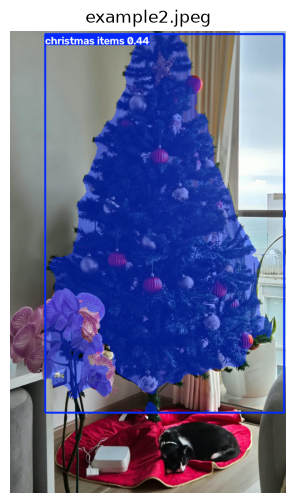

christmas items 0.44


In [21]:
yoloe.set_classes(["christmas items", "power adapter"])
results = yoloe(IMAGES, verbose=False)
show(results)

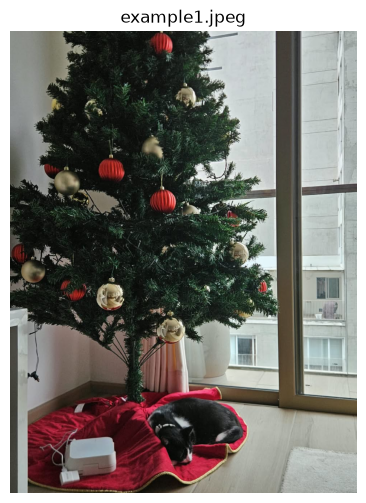

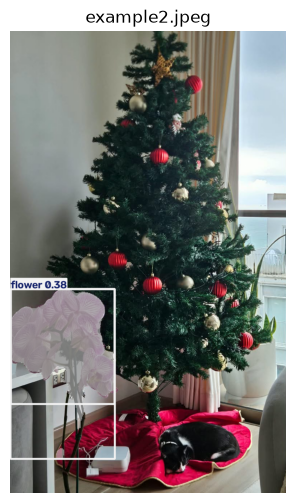

flower 0.38
flower 0.31


In [23]:
yoloe.set_classes(["ball", "window", "flower"])
results = yoloe(IMAGES, verbose=False)
show(results)

c:\Users\demo5\Documents\Apps\Case-YOLO\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


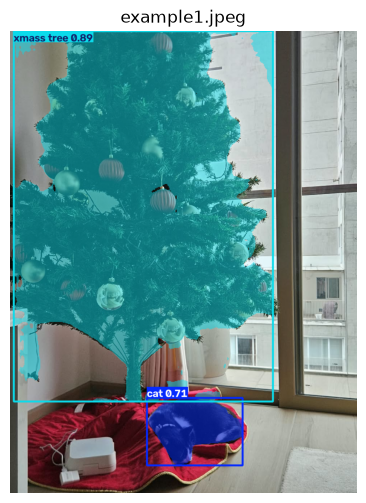

xmass tree 0.89
cat 0.71


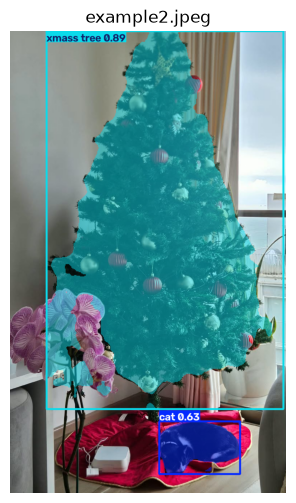

xmass tree 0.89
cat 0.63


In [24]:
yoloe.set_classes(["cat", "xmass tree", "tree"])
results = yoloe(IMAGES, verbose=False)
show(results)

c:\Users\demo5\Documents\Apps\Case-YOLO\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


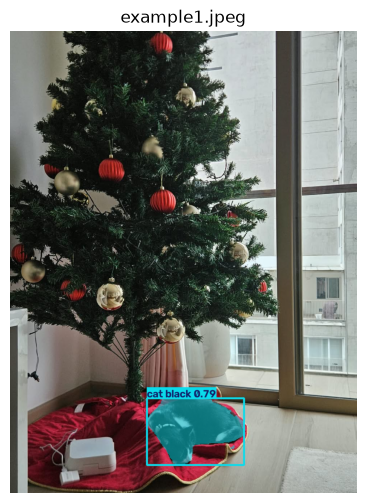

cat black 0.79


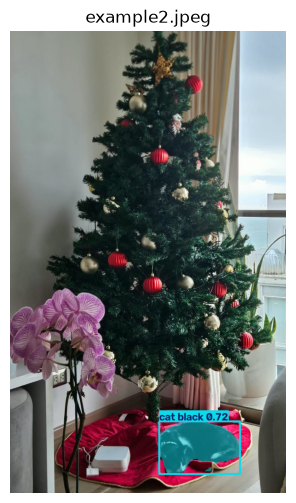

cat black 0.72


In [48]:
yoloe.set_classes(["cat","cat black", "cat sleeping"])
results = yoloe(IMAGES, verbose=False)
show(results)

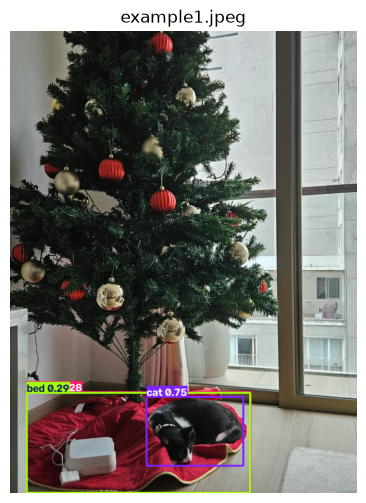

cat 0.75
bed 0.29
couch 0.28
----------------------------------------------------------------------
----------------------------------------------------------------------


c:\Users\demo5\Documents\Apps\Case-YOLO\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


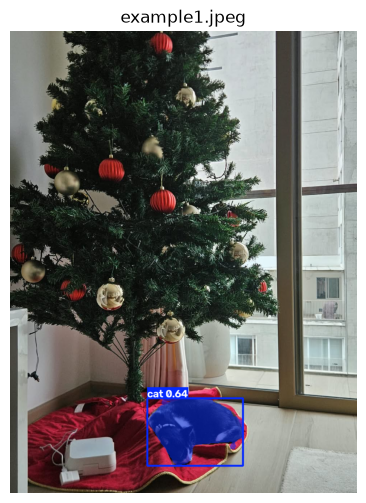

cat 0.64
----------------------------------------------------------------------


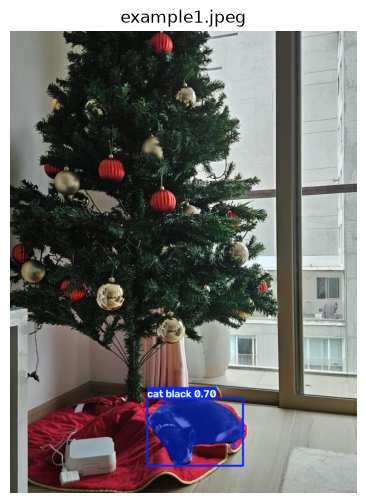

cat black 0.7
----------------------------------------------------------------------


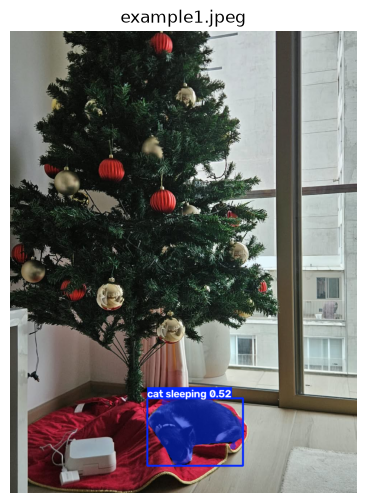

cat sleeping 0.52
----------------------------------------------------------------------


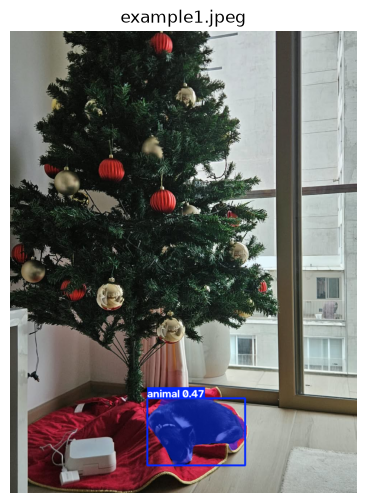

animal 0.47
----------------------------------------------------------------------


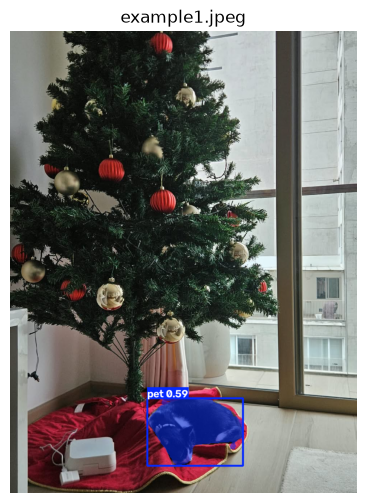

pet 0.59
----------------------------------------------------------------------


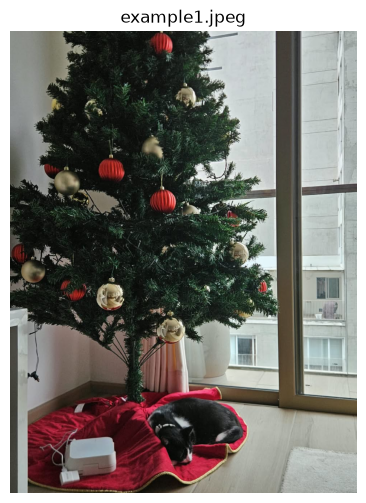

----------------------------------------------------------------------


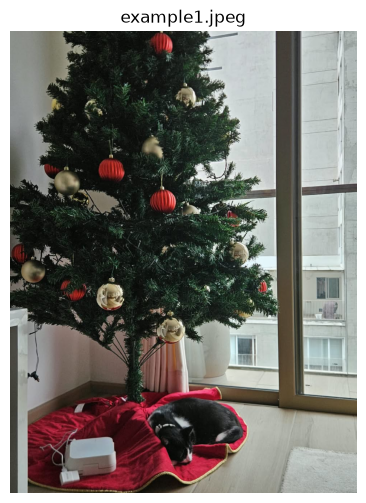

----------------------------------------------------------------------


In [38]:
list_values = ["cat","cat black", "cat sleeping", "animal", "pet", "white cat", "orange cat"]

# YOLO CLASSIC
results = yolo(IMAGES[0], verbose=False)
show(results)

print('-' * 70)
print('-' * 70)

# YOLOE
for value in list_values:
    yoloe.set_classes([value])
    results = yoloe(IMAGES[0], verbose=False)
    show(results)
    print("-" * 70)

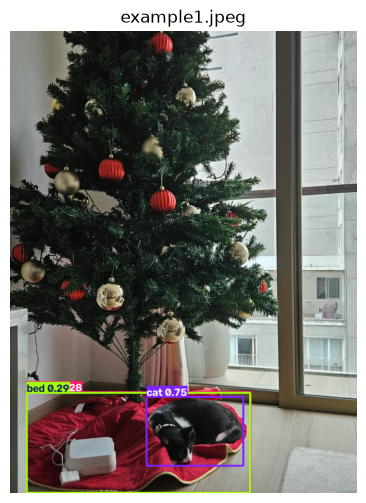

cat 0.75
bed 0.29
couch 0.28
----------------------------------------------------------------------
----------------------------------------------------------------------


c:\Users\demo5\Documents\Apps\Case-YOLO\.venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


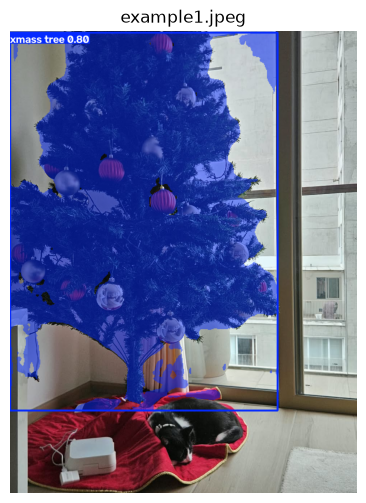

xmass tree 0.8
----------------------------------------------------------------------


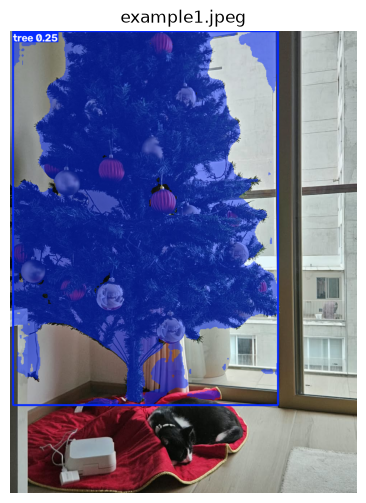

tree 0.25
----------------------------------------------------------------------


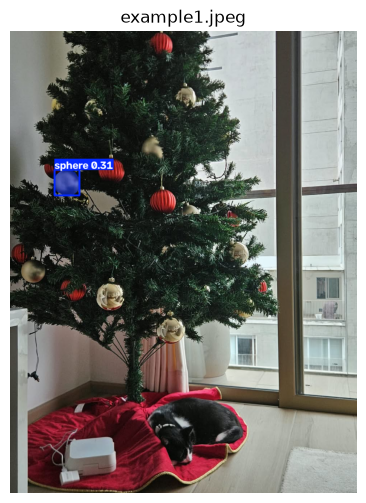

sphere 0.31
----------------------------------------------------------------------


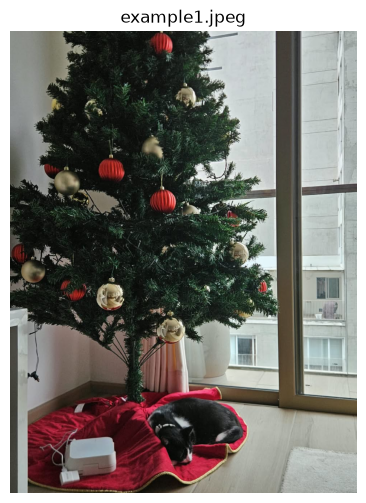

----------------------------------------------------------------------


In [40]:
list_values = ["xmass tree", "tree", "sphere", "ball"]

# YOLO CLASSIC
results = yolo(IMAGES[0], verbose=False)
show(results)

print('-' * 70)
print('-' * 70)

# YOLOE
for value in list_values:
    yoloe.set_classes([value])
    results = yoloe(IMAGES[0], verbose=False)
    show(results)
    print("-" * 70)

____